A small first analysis.

Under amplitude damping, there seems to be a tradeoff between

- postselecting (accepting fewer swap outcomes), which leads to lower probability of success,
- non-postselecting, which might reduce the average fidelity or secret key rate.

**Under amplitude damping, when is accepting fewer Bell outcomes worth the retries?**

The implementation supports accepting all corrected outcomes, the $\Phi$ pair, or the $\Psi$ pair. For normalized input links, the pair-acceptance probabilities depend on the $c_{IZ}$ and $c_{ZI}$ coefficients (population biases, which are zero for Bell-diagonal inputs but generally non-zero under damping), and differ between the $\Phi$ and $\Psi$ branches, which also lead to different postselected states.

**Can postselection extend the positive-key regime (Secret-Key-Rate)?**

In the two-pair example below, two already-relaxed Bell pairs are generated and swapped (deterministic generation and swapping). I am using $T_1$ and $T_2$ for noise (the notes now detail how these correlate to our noise parameters); we set $T_2=2T_1$ so we only have amplitude damping.

Postselecting on $\Psi$ gives stronger $XX$ correlation in the postselected state, which increases the secret-key-fraction (SKF) positive regime. Non-postselecting yields much higher probability (less waiting time), which then yields higher increases in the SKR (computed as: $\mathrm{SKR}=\mathrm{SKF}/\langle T\rangle$).


In [29]:
from copy import deepcopy
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/visualization").is_dir())
sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from src.visualization.config import DEFAULT
from src.visualization.evaluate import EvaluationService
from src.visualization.metrics import binary_entropy

policies = ("all_corrected", "phi_pair", "psi_pair")
styles = (("#0072B2", "-"), ("#CC79A7", "--"), ("#D55E00", ":"))
metrics = ("rate_bits_per_slot", "mean_wait_repository_slots", "eX", "eZ")
service = EvaluationService()

plt.rcParams.update({"font.size": 8})

panels = (("rate_bits_per_slot", "SKR (bits/slot)"),
          ("bb84_score", r"$1-h_2(e_X)-h_2(e_Z)$"),
          ("mean_wait_repository_slots", "Mean waiting time (slots)"))


In [30]:
# Two already-relaxed Phi+ pairs; no further waiting noise or preparation cost.
config = deepcopy(DEFAULT)
config["links"] = 2
config["hardware"].update(p_gen=1.0, p_swap=1.0)
config["protocol"]["tree"] = [0, 1]
config["memory"] = {"kind": "t1_t2", "t1_slots": None, "t2_slots": None}
prepared = []

for eta in np.linspace(0.905, 0.925, 81):
    t1 = -1 / np.log(eta)  # T1 in units of fixed prior storage time tau: eta = exp(-tau/T1).
    config["initial_state"] = {"kind": "real_x",
        "values": [1, 1-eta, 1-eta, eta**2+(1-eta)**2, eta, -eta]}
    for policy in policies:
        config["protocol"]["bell_outcomes"] = policy
        checked = []
        for horizon in (64, 128):
            config["numerics"]["t_trunc"] = horizon
            checked.append(service.evaluate(config).summary)
        short, long = checked
        assert min(short["coverage"], long["coverage"]) >= 0.999999
        assert np.allclose([short[k] for k in metrics], [long[k] for k in metrics],
                           rtol=1e-6, atol=1e-9)
        score = 1 - float(binary_entropy(long["eX"])) - float(binary_entropy(long["eZ"]))
        prepared.append({"T1": float(t1), "eta": float(eta), "policy": policy,
                         "bb84_score": score, **long})


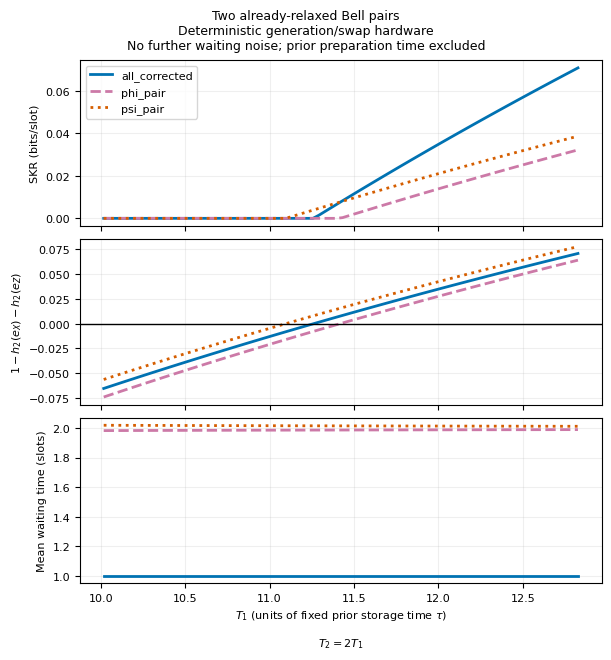

In [31]:
rows = prepared
title = ("Two already-relaxed Bell pairs\nDeterministic generation/swap hardware\n"
         "No further waiting noise; prior preparation time excluded")
xlabel = r"$T_1$ (units of fixed prior storage time $\tau$)"
scale = "linear"

fig, axes = plt.subplots(3, 1, figsize=(6, 6.5), dpi=100, sharex=True, layout="constrained")
for policy, (color, style) in zip(policies, styles):
    selected = [r for r in rows if r["policy"] == policy]
    for ax, (field, ylabel) in zip(axes, panels):
        ax.plot([r["T1"] for r in selected], [r[field] for r in selected],
                style, color=color, label=policy, linewidth=2)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.2)
axes[0].legend()
axes[1].axhline(0, color="black", linewidth=1)
axes[-1].set_xscale(scale)
axes[-1].set_xlabel(xlabel)
axes[-1].text(0.5, -0.32, r"$T_2=2T_1$", transform=axes[-1].transAxes,
              ha="center", va="top", fontsize=8)
fig.suptitle(title, fontsize=9)
plt.show()


**Second experiment: relaxation while waiting.**

Now start with four fresh Werner links ($F_0=0.97$), a balanced tree, probabilistic generation ($p_{\mathrm{gen}}=0.2$), and deterministic swap hardware. Noise acts during waiting, with $T_2=2T_1$. Compare the same three acceptance policies, without cutoffs or distillation.


In [32]:
# Four balanced links: waiting-time relaxation, fresh Werner inputs.
config = deepcopy(DEFAULT)
config["initial_state"]["fidelity"] = 0.97
config["hardware"].update(p_gen=0.2, p_swap=1.0)
relaxation = []

for t1 in np.geomspace(5, 4000, 61):
    config["memory"] = {"kind": "t1_t2", "t1_slots": float(t1), "t2_slots": float(2*t1)}
    for policy in policies:
        config["protocol"]["bell_outcomes"] = policy
        checked = []
        for horizon in (1024, 2048):
            config["numerics"]["t_trunc"] = horizon
            checked.append(service.evaluate(config).summary)
        short, long = checked
        assert min(short["coverage"], long["coverage"]) >= 0.999999
        assert np.allclose([short[k] for k in metrics], [long[k] for k in metrics],
                           rtol=1e-6, atol=1e-9)
        score = 1 - float(binary_entropy(long["eX"])) - float(binary_entropy(long["eZ"]))
        relaxation.append({"T1": float(t1), "policy": policy, "bb84_score": score, **long})


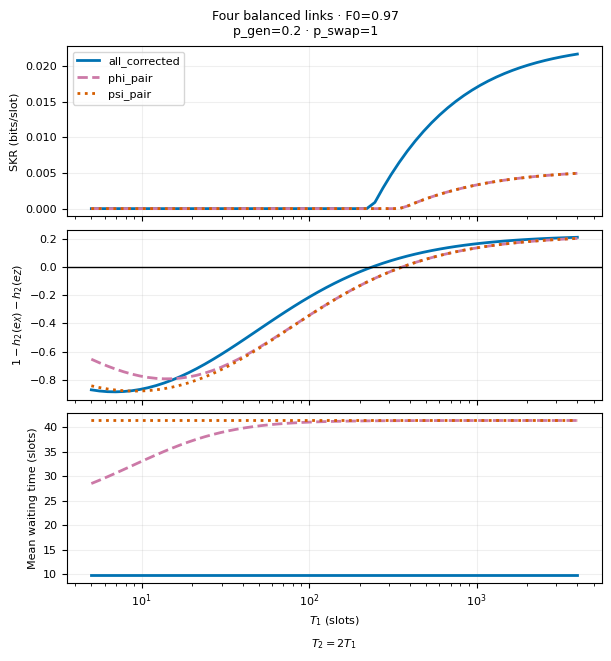

In [33]:
rows = relaxation
title = "Four balanced links · F0=0.97\np_gen=0.2 · p_swap=1"
xlabel = r"$T_1$ (slots)"
scale = "log"

fig, axes = plt.subplots(3, 1, figsize=(6, 6.5), dpi=100, sharex=True, layout="constrained")
for policy, (color, style) in zip(policies, styles):
    selected = [r for r in rows if r["policy"] == policy]
    for ax, (field, ylabel) in zip(axes, panels):
        ax.plot([r["T1"] for r in selected], [r[field] for r in selected],
                style, color=color, label=policy, linewidth=2)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.2)
axes[0].legend()
axes[1].axhline(0, color="black", linewidth=1)
axes[-1].set_xscale(scale)
axes[-1].set_xlabel(xlabel)
axes[-1].text(0.5, -0.32, r"$T_2=2T_1$", transform=axes[-1].transAxes,
              ha="center", va="top", fontsize=8)
fig.suptitle(title, fontsize=9)
plt.show()


Here, accepting all outcomes gives the highest SKR and positive key at shorter $T_1$. Postselection narrows the positive-key regime in this family, unlike the already-relaxed two-pair example. Under strong damping, $\Phi$ selection improves the unclipped BB84 score, but it stays negative; this quality benefit is insufficient to produce key.

In this plot, the mean waiting time depend on $T_1$ only for the $\Phi$ selection (actually, also for $\Psi$ but is not visible).
Large positive Φ biases make Φ acceptance more likely under strong damping.
This is because relaxation pushes excited popolations toward $\ket 0$ and when both qubits undergoing Bell measurement become biased toward 0, measuring 00 is more likely, increasing the $\Phi$ branch probability.

**Third experiment: source imbalance and network size.**

Before damping, each source prepares
$|\psi_q\rangle=\sqrt{1-q}|00\rangle+\sqrt{q}|11\rangle$.
Compare Bell sources ($q=1/2$) with partially entangled sources ($q=1/4$).
Apply independent amplitude damping to both qubits for a fixed time $\tau$:
$\eta=\exp(-\tau/T_1)$, with $T_2=2T_1$. Connect 2, 4, 8, or 16 links using a balanced tree and one global acceptance policy.

There is no additional waiting noise, cutoff, or distillation. Find the critical $T_1/\tau$ where the unclipped BB84 score crosses zero; key is positive above it. Thresholds use the backend swap maps directly. Since accepted swaps have nonzero probability and finite retry times here, a positive SKF gives positive SKR. A full timing check follows below. 


In [34]:
import pandas as pd
from IPython.display import display
from src.core.pauli_adc.protocol_units import accepted_bell_swap

sizes = (2, 4, 8, 16)
scaling = []
for q in (0.5, 0.25):
    for links in sizes:
        thresholds = {}
        for policy in ("all_corrected", "psi_pair"):
            low, high = 0.5, 1.0
            for _ in range(48):  # Bisection of the zero of the unclipped BB84 score.
                eta = (low + high)/2
                state = np.array([1, 1-2*q*eta, 1-2*q*eta,
                                  1-4*q*eta*(1-eta),
                                  2*np.sqrt(q*(1-q))*eta, -2*np.sqrt(q*(1-q))*eta])
                for level in range(links.bit_length()-1):
                    state, probability = accepted_bell_swap(state, state,
                                                           outcomes=policy, conditioned=True)
                    assert probability > 0
                score = 1-float(binary_entropy((1-state[4])/2))-float(binary_entropy((1-state[3])/2))
                if score > 0:
                    high = eta
                else:
                    low = eta
            assert abs(score) < 1e-10
            thresholds[policy] = -1/np.log((low+high)/2)
        scaling.append({"q": q, "Links": links, "All: T1/tau": thresholds["all_corrected"],
                        "Psi: T1/tau": thresholds["psi_pair"],
                        "Reduction (%)": 100*(1-thresholds["psi_pair"]/thresholds["all_corrected"])})
scaling = pd.DataFrame(scaling)


,All: T1/tau,Psi: T1/tau,Reduction (%)
Links,,,
2,14.21,7.69,45.88
4,57.66,15.44,73.23
8,463.49,30.86,93.34
16,13454.96,61.72,99.54


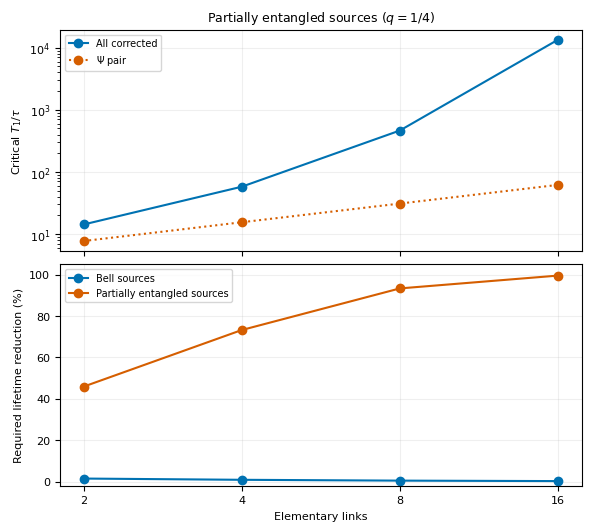

In [35]:
imbalanced = scaling[scaling["q"] == 0.25]
display(imbalanced.drop(columns="q").set_index("Links").round(2))

fig, axes = plt.subplots(2, 1, figsize=(5.8, 5.2), dpi=100, sharex=True, layout="constrained")
for field, label, color, style in (
    ("All: T1/tau", "All corrected", "#0072B2", "-o"),
    ("Psi: T1/tau", r"$\Psi$ pair", "#D55E00", ":o"),
):
    axes[0].plot(imbalanced["Links"], imbalanced[field], style, color=color, label=label)
axes[0].set_yscale("log")
axes[0].set_ylabel(r"Critical $T_1/\tau$")
axes[0].set_title(r"Partially entangled sources ($q=1/4$)", fontsize=9)
for q, label, color in ((0.5, "Bell sources", "#0072B2"),
                        (0.25, "Partially entangled sources", "#D55E00")):
    selected = scaling[scaling["q"] == q]
    axes[1].plot(selected["Links"], selected["Reduction (%)"], "-o", color=color, label=label)
axes[1].set_ylabel("Required lifetime reduction (%)")
axes[1].set_ylim(-2, 105)
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(sizes, [str(n) for n in sizes])
axes[1].set_xlabel("Elementary links")
for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)
plt.show()


For Bell sources, the relative lifetime advantage shrinks from 1.46% to 0.24%. With $q=1/4$, it grows from 45.9% to 99.5%. $\Psi$ selection concentrates entanglement by favoring more balanced end-to-end amplitudes; repeated unselected swapping suppresses the transverse correlations of imbalanced sources. This larger effect includes source imbalance alongside relaxation.

**Timing check: four links, $q=1/4$, $T_1/\tau=25$.** Compare actual SKR, including rejection and retries, at horizons 128 and 256. Prior state-preparation time remains excluded; a large positive-region extension alone does not guarantee useful throughput.


In [36]:
q, eta = 0.25, np.exp(-1/25)
initial = [1, 1-2*q*eta, 1-2*q*eta, 1-4*q*eta*(1-eta),
           2*np.sqrt(q*(1-q))*eta, -2*np.sqrt(q*(1-q))*eta]
config = deepcopy(DEFAULT)
config["links"] = 4
config["protocol"]["tree"] = [[0, 1], [2, 3]]
config["initial_state"] = {"kind": "real_x", "values": initial}
config["hardware"].update(p_gen=1.0, p_swap=1.0)
config["memory"] = {"kind": "t1_t2", "t1_slots": None, "t2_slots": None}
timing = []

for policy in ("all_corrected", "psi_pair"):
    config["protocol"]["bell_outcomes"] = policy
    checked = []
    for horizon in (128, 256):
        config["numerics"]["t_trunc"] = horizon
        checked.append(service.evaluate(config).summary)
    short, long = checked
    assert min(short["coverage"], long["coverage"]) >= 0.999999
    assert np.allclose([short[k] for k in metrics], [long[k] for k in metrics],
                       rtol=1e-6, atol=1e-9)
    state = initial
    for level in range(2):
        state, _ = accepted_bell_swap(state, state, outcomes=policy, conditioned=True)
    assert np.allclose(long["pooled_coordinates"], state, atol=1e-10, rtol=0)
    timing.append({"Acceptance": policy, "SKF": long["pooled_secret_fraction"],
                   "Mean wait (slots)": long["mean_wait_repository_slots"],
                   "SKR (bits/slot)": long["rate_bits_per_slot"]})
display(pd.DataFrame(timing).set_index("Acceptance").round(5))


,SKF,Mean wait (slots),SKR (bits/slot)
Acceptance,,,
all_corrected,0.00000,1.00000,0.0000
psi_pair,0.25465,7.60197,0.0335


**Fourth experiment: relaxation while waiting, source imbalance, and network size.**

Start with $L=2^n$ fresh links ($n=1,2,3$), a balanced tree, $p_{\mathrm{gen}}=0.2$, and instantaneous deterministic swap hardware. Compare the third experiment's pure sources $|\psi_q\rangle=\sqrt{1-q}|00\rangle+\sqrt q|11\rangle$: Bell ($q=1/2$, $F_0=1$) and partially entangled (PE, $q=1/4$). These sources have different initial entanglement; this is not an equal-fidelity comparison with the second experiment's Werner inputs.

Noise acts **only during waiting**, at every nesting level: $\kappa=1/T_1$, no pure dephasing, hence $T_2=2T_1$. There is no fixed prior storage time $\tau$ here; $T_1$ is measured in slots. Apply each global acceptance policy at every swap, with destructive retries, no cutoffs, and no distillation. Include $T_1=\infty$ as a control for source imbalance alone.

Compare pooled SKF, mean waiting time, and $\mathrm{SKR}=\mathrm{SKF}/\langle T\rangle$. Does postselection still give positive SKR where accepting all outcomes gives zero, and how does this change with size? Sweep $T_1$ from 5 to $10^4$ slots on 36 logarithmic points, plus the noise-free control. All-outcome runs start at horizons 1024/2048; postselected runs start at 2048/4096 and can extend to 65536. The grid is exploratory: refine transition intervals before quoting lifetime reductions. Every plotted point must pass coverage and doubled-horizon checks; failed points stay missing. Run the shared imports and these cells; the earlier sweeps need not be rerun.

For the sampled-positive summary, require SKF $>10^{-9}$; confirm the marginal cases on a finer grid. Backend validation failures are listed explicitly, not interpreted as zero key.

In [ ]:
# Use the backend directly: the visualization configuration intentionally stops at 8 links.
import pandas as pd
from IPython.display import display
from src.core.pauli_adc.state import RealXState
from src.core.repeater_algorithm import RepeaterChainEvaluation
from src.visualization.protocols import compile_protocol
from src.visualization.metrics import summarize, validate_outputs

noise_sizes = (2, 4, 8)
noise_sources = ((0.5, "Bell"), (0.25, "PE"))
noise_t1 = np.r_[np.geomspace(5, 1e4, 36), np.inf]
noise_horizons = {
    "all_corrected": (1024, 2048, 4096, 8192),
    "phi_pair": (2048, 4096, 8192, 16384, 32768, 65536),
    "psi_pair": (2048, 4096, 8192, 16384, 32768, 65536),
}
noise_metrics = ("rate_bits_per_slot", "pooled_secret_fraction", "mean_wait_repository_slots", "eX", "eZ")
noise_evaluator = RepeaterChainEvaluation(state_type=RealXState, efficient=True,
                                         use_fft=True, use_gpu=False, w_twirling=False)


In [ ]:
waiting_noise = []
for q, source in noise_sources:
    initial = [1, 1-2*q, 1-2*q, 1, 2*np.sqrt(q*(1-q)), -2*np.sqrt(q*(1-q))]
    for links in noise_sizes:
        layer = list(range(links))
        while len(layer) > 1:
            layer = [[layer[i], layer[i+1]] for i in range(0, len(layer), 2)]
        protocol = deepcopy(DEFAULT["protocol"])
        protocol.update(tree=layer[0], distillation_rounds={}, memory_cutoff_slots=None,
                        cutoff_overrides={})
        for t1 in noise_t1:
            for policy in policies:
                previous, summary, converged, error = None, {}, False, None
                try:
                    for horizon in noise_horizons[policy]:
                        sequence, operations = compile_protocol(protocol, links, horizon)
                        parameters = dict(protocol=sequence, p_gen=[0.2]*links, p_swap=1.0,
                            p_distillation=1.0, real_x_coordinates=[initial]*links,
                            pauli_mode_decay_rates=[[0., 0., 0.]]*(links+1),
                            amplitude_damping_rate=[0. if np.isinf(t1) else 1/float(t1)]*(links+1),
                            bell_outcomes=policy, real_x_werner_twirling=False,
                            cutoff=[op["backend_cutoff"] for op in operations],
                            cut_type="memory_time", t_trunc=horizon)
                        pmf, x = noise_evaluator.asymmetric_heterogeneous_protocol(parameters, links)
                        pmf, x, _ = validate_outputs(pmf, x, horizon)
                        summary, _ = summarize(pmf, x, coverage_target=0.999999)
                        if (previous is not None and min(previous["coverage"], summary["coverage"]) >= 0.999999
                                and np.allclose([previous[k] for k in noise_metrics],
                                                [summary[k] for k in noise_metrics], rtol=1e-6, atol=1e-9)):
                            converged = True
                            break
                        previous = summary
                    if not converged:
                        error = "Horizon check failed; extend noise_horizons."
                except ValueError as exc:
                    error = str(exc)
                if not converged:
                    summary = {**summary, "status": "failed", **{k: np.nan for k in noise_metrics}}
                waiting_noise.append({"source": source, "q": q, "Links": links, "T1": float(t1),
                    "policy": policy, "converged": converged, "horizon": horizon, "error": error, **summary})
        print(f"{source}: {links} links finished")
waiting_noise = pd.DataFrame(waiting_noise)
noise_free = waiting_noise[np.isinf(waiting_noise["T1"])].copy()
failures = waiting_noise[~waiting_noise["converged"]]
if not failures.empty:
    display(failures[["source", "Links", "T1", "policy", "horizon", "error"]])


Bell: 2 links finished
Bell: 4 links finished
Bell: 8 links finished
PE: 2 links finished
PE: 4 links finished
PE: 8 links finished


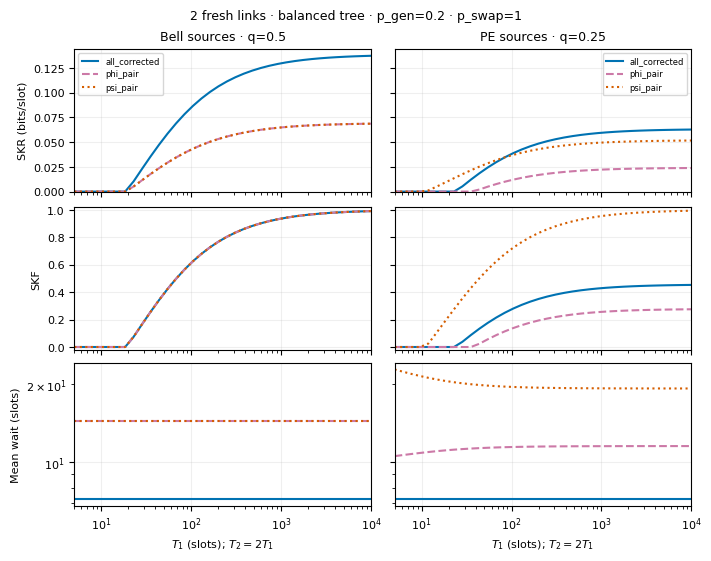

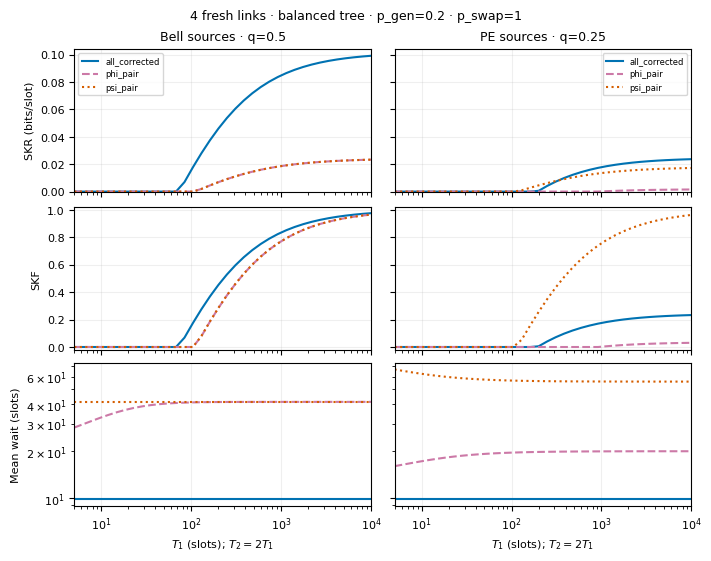

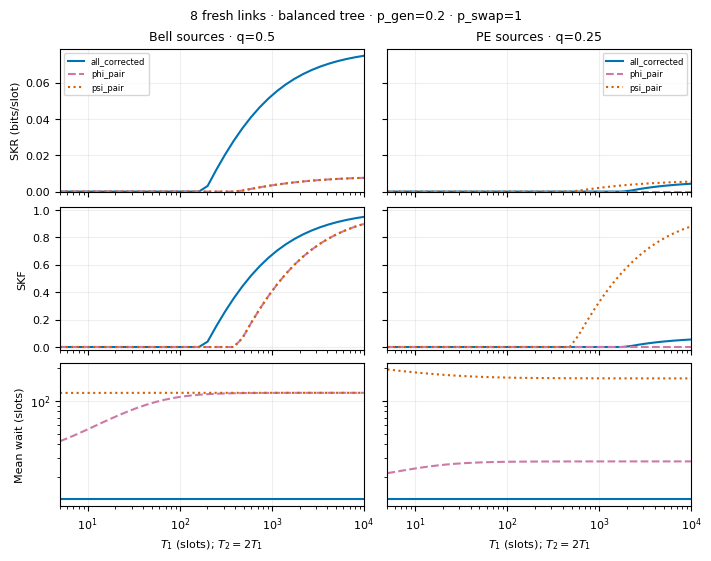

In [ ]:
# One compact figure per size; source columns share the same metric scales.
noise_panels = (("rate_bits_per_slot", "SKR (bits/slot)"),
                ("pooled_secret_fraction", "SKF"),
                ("mean_wait_repository_slots", "Mean wait (slots)"))
for links in noise_sizes:
    fig, axes = plt.subplots(3, 2, figsize=(7, 5.5), dpi=100, sharex=True,
                             sharey="row", layout="constrained")
    for column, (q, source) in enumerate(noise_sources):
        axes[0, column].set_title(f"{source} sources · q={q:g}", fontsize=9)
        for policy, (color, style) in zip(policies, styles):
            selected = waiting_noise[(waiting_noise["Links"] == links) & (waiting_noise["q"] == q)
                                    & (waiting_noise["policy"] == policy) & np.isfinite(waiting_noise["T1"])]
            for row, (field, ylabel) in enumerate(noise_panels):
                ax = axes[row, column]
                ax.plot(selected["T1"], selected[field], style, color=color, label=policy, linewidth=1.5)
                ax.set_xscale("log")
                ax.set_xlim(noise_t1[0], noise_t1[np.isfinite(noise_t1)][-1])
                ax.grid(alpha=0.2)
                if column == 0:
                    ax.set_ylabel(ylabel)
        axes[0, column].legend(fontsize=6)
        axes[0, column].set_ylim(bottom=0)
        axes[1, column].set_ylim(-0.02, 1.02)
        axes[2, column].set_yscale("log")
        axes[2, column].set_xlabel(r"$T_1$ (slots); $T_2=2T_1$")
    fig.suptitle(f"{links} fresh links · balanced tree · p_gen=0.2 · p_swap=1", fontsize=9)
    plt.show()


In [ ]:
# First positive sampled point, not a fitted threshold; controls remain in noise_free.
# Never infer a boundary or an exclusive advantage through failed/unconverged points.
noise_boundaries = []
for (source, links), group in waiting_noise.groupby(["source", "Links"], sort=False):
    finite = group[np.isfinite(group["T1"])]
    row = {"Source": source, "Links": links}
    fractions = finite.pivot(index="T1", columns="policy", values="pooled_secret_fraction")
    for policy in policies:
        positive = finite[(finite["policy"] == policy) & (finite["pooled_secret_fraction"] > 1e-9)]
        row[f"{policy}: first positive T1 (sampled)"] = positive["T1"].min()
        if policy != "all_corrected":
            row[f"{policy}: exclusive positive points"] = int(
                ((fractions[policy] > 1e-9) & (fractions["all_corrected"] == 0)).sum())
    noise_boundaries.append(row)
display(pd.DataFrame(noise_boundaries).set_index(["Source", "Links"]).round(2))


all_corrected: first positive T1 (sampled)  ...  psi_pair: exclusive positive points
Source Links                                              ...                                     
Bell   2                                           22.87  ...                                    0
       4                                           84.15  ...                                    0
       8                                          200.60  ...                                    0
PE     2                                           28.41  ...                                    4
       4                                          200.60  ...                                    2
       8                                         2186.72  ...                                    6

[6 rows x 5 columns]

All 666 points converged with coverage at least $0.999999$ and consistent doubled-horizon metrics. The sweep spans $5\leq T_1\leq 10^4$ slots on 36 logarithmic points, plus a noise-free control. Final horizons were 2048 for all outcomes, 4096 for most postselected points, and 8192 for some eight-link PE/$\Psi$ points.

[Saved data](../../results/analysis/fourth-waiting-noise-20261022T100514Z/sweep.csv) and [run settings](../../results/analysis/fourth-waiting-noise-20261022T100514Z/setup.json).

**Fifth experiment: select only at the final swap.**

Use four fresh Bell links ($F_0=1$), a balanced tree, $p_{\mathrm{gen}}=0.2$, deterministic swap hardware, and waiting-time relaxation with $T_2=2T_1$. No preparation damping, cutoffs, or distillation.

Compare accepting all outcomes, selecting $\Psi$ everywhere, and accepting all at the two first-level swaps but selecting $\Psi$ at the final swap. The last choice uses outcome information after waiting has damaged the links, while avoiding lower-level rejection and its additional waiting noise. This is a placement experiment: it extends the fourth experiment's global-policy comparison. Compose existing backend swap units here; the app's global policy remains unchanged.

Near the positive-key boundary, stronger $XX$ correlations can outweigh the final retries. Check both the positive region and actual pooled SKR; the gain need not persist at larger $T_1$.

In [41]:
from src.core.pauli_adc.state import RealXState
from src.core.repeater_algorithm import RepeaterChainEvaluation
from src.visualization.metrics import summarize, validate_outputs
import pandas as pd
from IPython.display import display

schedules = (("All outcomes", "all_corrected", "all_corrected", "#0072B2", "-"),
             ("Global Ψ", "psi_pair", "psi_pair", "#D55E00", ":"),
             ("Final-only Ψ", "all_corrected", "psi_pair", "#009E73", "--"))
final_evaluator = RepeaterChainEvaluation(state_type=RealXState, efficient=True,
                                         use_fft=True, use_gpu=False, w_twirling=False)
final_selection = []
for t1 in np.linspace(70, 82, 49):
    for label, lower, upper, color, style in schedules:
        checked = []
        for horizon in (512, 1024):
            parameters = dict(p_gen=0.2, p_swap=1.0, t_trunc=horizon, cutoff=horizon,
                cut_type="memory_time", real_x_coordinates=[1., 0., 0., 1., 1., -1.],
                pauli_mode_decay_rates=[0., 0., 0.], amplitude_damping_rate=1/float(t1),
                real_x_werner_twirling=False)
            # Each first-level subtree contains two independent elementary links.
            pmf, x = final_evaluator.nested_protocol(dict(parameters, protocol=(0,), bell_outcomes=lower))
            # Two independent copies of that subtree are joined at the root.
            pmf, x = final_evaluator.compute_unit(dict(parameters, bell_outcomes=upper),
                                                 pmf, x, unit_kind="swap")
            pmf, x, _ = validate_outputs(pmf, x, horizon)
            summary, _ = summarize(pmf, x, coverage_target=0.999999)
            checked.append(summary)
        short, long = checked
        assert min(short["coverage"], long["coverage"]) >= 0.999999
        assert np.allclose([short[k] for k in metrics], [long[k] for k in metrics],
                           rtol=1e-6, atol=1e-9)
        final_selection.append({"T1": float(t1), "Schedule": label, **long})
final_selection = pd.DataFrame(final_selection)


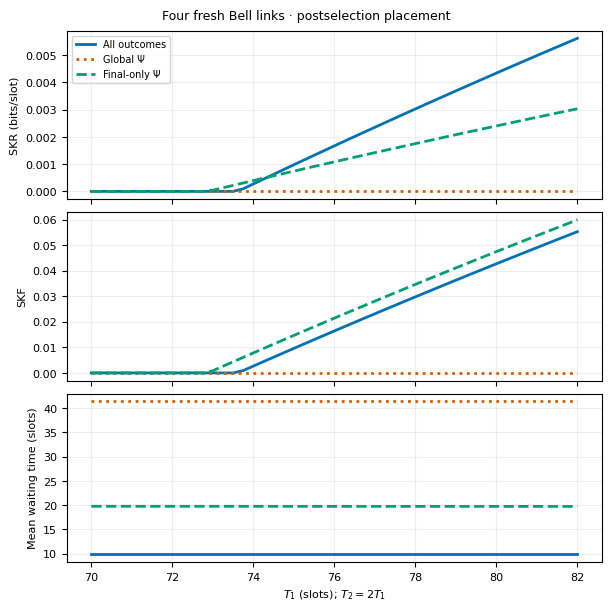

SKF  Mean wait (slots)  SKR (bits/slot)
T1   Schedule                                                  
73.5 All outcomes  0.000000           9.836288         0.000000
     Global Ψ      0.000000          41.404539         0.000000
     Final-only Ψ  0.004349          19.767128         0.000220
74.0 All outcomes  0.002677           9.836288         0.000272
     Global Ψ      0.000000          41.404539         0.000000
     Final-only Ψ  0.007820          19.765962         0.000396

In [42]:
fig, axes = plt.subplots(3, 1, figsize=(6, 6), dpi=100, sharex=True, layout="constrained")
for label, lower, upper, color, style in schedules:
    selected = final_selection[final_selection["Schedule"] == label]
    for ax, (field, ylabel) in zip(axes, (
        ("rate_bits_per_slot", "SKR (bits/slot)"),
        ("pooled_secret_fraction", "SKF"),
        ("mean_wait_repository_slots", "Mean waiting time (slots)"),
    )):
        ax.plot(selected["T1"], selected[field], style, color=color, label=label, linewidth=2)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.2)
axes[0].legend(fontsize=7)
axes[-1].set_xlabel(r"$T_1$ (slots); $T_2=2T_1$")
fig.suptitle("Four fresh Bell links · postselection placement", fontsize=9)
plt.show()

point_comparison = final_selection[final_selection["T1"].isin([73.5, 74.])]
display(point_comparison.set_index(["T1", "Schedule"])[[
    "pooled_secret_fraction", "mean_wait_repository_slots", "rate_bits_per_slot"
]].rename(columns={"pooled_secret_fraction": "SKF", "mean_wait_repository_slots": "Mean wait (slots)",
                   "rate_bits_per_slot": "SKR (bits/slot)"}).round(7))


At $T_1=73.5$, final-only $\Psi$ gives positive SKR while the other two schedules give zero. At $T_1=74$, SKF rises from about $0.00268$ to $0.00782$, enough to pay for roughly twice the waiting time: SKR increases by about $45\%$. At $T_1=75$, accepting all already wins again. Global $\Psi$ selection lengthens lower-level preparation and gives no key throughout this window.

Bisection of the unclipped BB84 score places the critical lifetimes near $73.618$ slots (all outcomes) and $72.879$ slots (final-only $\Psi$): about a $1.0\%$ reduction. The important new ingredient is **where** we postselect, with the source and all hardware held fixed.